In [1]:
%pip -q install "transformers>=4.45,<5" accelerate

from pathlib import Path
import pandas as pd
import torch

from google.colab import drive
drive.mount("/content/drive")

DATA_ROOT = Path(
    "/content/drive/MyDrive/Cellula/"
    "Shoplifting-Detection/DataSet"
)

SPLIT_PATH = (
    DATA_ROOT
    / "shoplifting_independent_v6_no_attention"
    / "video_split.csv"
)

assert SPLIT_PATH.is_file(), (
    f"Existing split not found: {SPLIT_PATH}"
)

manifest = pd.read_csv(SPLIT_PATH)

assert len(manifest) == 632
assert manifest["sha256"].is_unique
assert set(manifest["split"]) == {"train", "test"}

manifest["video_path"] = manifest["relative_path"].apply(
    lambda p: str(DATA_ROOT / p)
)

assert all(
    Path(p).is_file()
    for p in manifest["video_path"]
)

print(pd.crosstab(
    manifest["split"],
    manifest["class_name"]
))

print("\nVideos with fewer than 16 sampled frames:")
print((manifest["sampled_frames"] < 16).sum())

print("\nVideos with 16 or more sampled frames:")
print((manifest["sampled_frames"] >= 16).sum())

print("\nDevice:", "CUDA" if torch.cuda.is_available() else "CPU")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
Mounted at /content/drive
class_name  Normal  Shoplifting
split                          
test            47           48
train          263          274

Videos with fewer than 16 sampled frames:
462

Videos with 16 or more sampled frames:
170

Device: CUDA


In [2]:
from transformers import (
    VideoMAEImageProcessor,
    VideoMAEForVideoClassification
)

MODEL_ID = "MCG-NJU/videomae-small-finetuned-kinetics"

processor = VideoMAEImageProcessor.from_pretrained(
    MODEL_ID
)

model = VideoMAEForVideoClassification.from_pretrained(
    MODEL_ID,
    num_labels=2,
    id2label={0: "Normal", 1: "Shoplifting"},
    label2id={"Normal": 0, "Shoplifting": 1},
    ignore_mismatched_sizes=True
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.eval()

print("Model:", MODEL_ID)
print("Input frames:", model.config.num_frames)
print("Image size:", model.config.image_size)
print("Classifier:", model.classifier)
print("Processor mean:", processor.image_mean)
print("Processor std:", processor.image_std)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

# Sanity check with synthetic video input
x = torch.zeros(
    1,
    model.config.num_frames,
    3,
    model.config.image_size,
    model.config.image_size,
    device=device
)

with torch.inference_mode():
    y = model(pixel_values=x).logits

assert y.shape == (1, 2)

print("Output shape:", tuple(y.shape))
print("Model loading and forward pass: PASS")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Some weights of VideoMAEForVideoClassification were not initialized from the model checkpoint at MCG-NJU/videomae-small-finetuned-kinetics and are newly initialized because the shapes did not match:
- classifier.weight: found shape torch.Size([400, 384]) in the checkpoint and torch.Size([2, 384]) in the model instantiated
- classifier.bias: found shape torch.Size([400]) in the checkpoint and torch.Size([2]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Model: MCG-NJU/videomae-small-finetuned-kinetics
Input frames: 16
Image size: 224
Classifier: Linear(in_features=384, out_features=2, bias=True)
Processor mean: [0.485, 0.456, 0.406]
Processor std: [0.229, 0.224, 0.225]
Parameters: 21880706


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Output shape: (1, 2)
Model loading and forward pass: PASS


In [3]:

# 3 — Configuration and validation split

import random, time, json
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageEnhance
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

OUT = DATA_ROOT / "shoplifting_pretrained_videomae_small"
OUT.mkdir(parents=True, exist_ok=True)

# Local Colab cache, not permanent Google Drive storage.
CACHE_DIR = Path("/content/videomae_cache_16f_224")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

NUM_FRAMES = int(model.config.num_frames)
IMAGE_SIZE = int(model.config.image_size)

assert NUM_FRAMES == 16
assert IMAGE_SIZE == 224

FLIP_PROB = 0.50
COLOR_JITTER = 0.15

MEAN = np.asarray(
    processor.image_mean, dtype=np.float32
).reshape(1, 1, 1, 3)

STD = np.asarray(
    processor.image_std, dtype=np.float32
).reshape(1, 1, 1, 3)

# IMPORTANT:
# We never call the processor for image transformations.
# Manual resize -> normalization, with NO CROP.
print("Center crop enabled in original processor:",
      getattr(processor, "do_center_crop", None))
print("Our pipeline: direct resize, NO CROP")

train_full = manifest[
    manifest["split"] == "train"
].reset_index(drop=True)

test_rows = manifest[
    manifest["split"] == "test"
].reset_index(drop=True)

train_rows, val_rows = train_test_split(
    train_full,
    test_size=0.15,
    random_state=SEED,
    stratify=train_full["label"]
)

train_rows = train_rows.reset_index(drop=True)
val_rows = val_rows.reset_index(drop=True)

train_hashes = set(train_rows.sha256)
val_hashes = set(val_rows.sha256)
test_hashes = set(test_rows.sha256)

assert not (train_hashes & val_hashes)
assert not (train_hashes & test_hashes)
assert not (val_hashes & test_hashes)

print("\nDataset splits:")
for name, rows in [
    ("Train", train_rows),
    ("Validation", val_rows),
    ("Test (untouched for tuning)", test_rows)
]:
    print(name, len(rows), rows.label.value_counts().to_dict())

print("\nFrames:", NUM_FRAMES)
print("Resolution:", IMAGE_SIZE)
print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "Not available")

Center crop enabled in original processor: True
Our pipeline: direct resize, NO CROP

Dataset splits:
Train 456 {1: 233, 0: 223}
Validation 81 {1: 41, 0: 40}
Test (untouched for tuning) 95 {1: 48, 0: 47}

Frames: 16
Resolution: 224
GPU: Tesla T4


In [4]:

# 4 — 1 FPS sampling + exactly 16 RGB frames
# NO CENTER CROP / RANDOM CROP / RESIZED CROP

def extract_video_frames(path):
    cap = cv2.VideoCapture(str(path))

    if not cap.isOpened():
        raise RuntimeError(f"Cannot open video: {path}")

    try:
        fps = float(cap.get(cv2.CAP_PROP_FPS))
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if not np.isfinite(fps) or fps <= 0 or total <= 0:
            raise ValueError(f"Invalid video metadata: {path}")

        # Original pipeline: sample at 1 FPS.
        seconds = np.arange(0, total / fps, 1.0)
        sample_ids = np.rint(seconds * fps).astype(np.int64)
        sample_ids = np.unique(np.clip(sample_ids, 0, total - 1))

        if len(sample_ids) == 0:
            raise RuntimeError(f"No sampled frames: {path}")

        # Uniformly select 16 positions from 1 FPS samples.
        # Short videos repeat positions; no spatial crop.
        positions = np.rint(
            np.linspace(0, len(sample_ids) - 1, NUM_FRAMES)
        ).astype(int)

        chosen_ids = sample_ids[positions]

        frames = []
        for idx in chosen_ids:
            cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
            ok, bgr = cap.read()

            if not ok or bgr is None:
                raise RuntimeError(
                    f"Failed decoding frame {idx}: {path}"
                )

            # Resize entire frame. Nothing is cropped.
            bgr = cv2.resize(
                bgr,
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=cv2.INTER_AREA
            )

            rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
            frames.append(rgb)

        return np.stack(frames).astype(np.uint8)

    finally:
        cap.release()


def get_cached_clip(row):
    cache_path = CACHE_DIR / (
        f"{row['sha256']}_{NUM_FRAMES}f_{IMAGE_SIZE}.npy"
    )

    if not cache_path.exists():
        frames = extract_video_frames(row["video_path"])
        np.save(cache_path, frames)

    frames = np.load(cache_path, allow_pickle=False)

    assert frames.shape == (
        NUM_FRAMES, IMAGE_SIZE, IMAGE_SIZE, 3
    )
    assert frames.dtype == np.uint8

    return frames


# Pre-cache TRAIN and VALIDATION only.
# Test videos are decoded later, during final evaluation.
precache_rows = pd.concat(
    [train_rows, val_rows], ignore_index=True
)

for row in tqdm(
    precache_rows.to_dict("records"),
    desc="Preparing VideoMAE frame cache"
):
    get_cached_clip(row)

print("Train/validation frame cache ready.")
print("No crop applied.")

Preparing VideoMAE frame cache:   0%|          | 0/537 [00:00<?, ?it/s]

Train/validation frame cache ready.
No crop applied.


Sample tensor shape: torch.Size([16, 3, 224, 224])
Sample label: 1


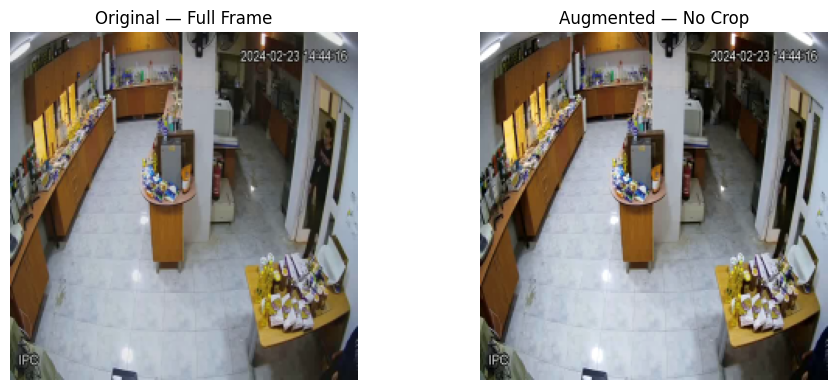

In [5]:

# 5 — Temporally consistent augmentation and dataset

def augment_clip(frames):
    flip = random.random() < FLIP_PROB

    brightness = random.uniform(
        1 - COLOR_JITTER, 1 + COLOR_JITTER
    )
    contrast = random.uniform(
        1 - COLOR_JITTER, 1 + COLOR_JITTER
    )
    saturation = random.uniform(
        1 - COLOR_JITTER, 1 + COLOR_JITTER
    )

    if flip:
        frames = frames[:, :, ::-1, :]

    result = []

    for frame in frames:
        image = Image.fromarray(
            np.ascontiguousarray(frame)
        )

        image = ImageEnhance.Brightness(
            image
        ).enhance(brightness)

        image = ImageEnhance.Contrast(
            image
        ).enhance(contrast)

        image = ImageEnhance.Color(
            image
        ).enhance(saturation)

        result.append(np.asarray(image, dtype=np.uint8))

    return np.stack(result)


def frames_to_tensor(frames):
    # Model-specific normalization; not V6's [-1, 1].
    x = frames.astype(np.float32) / 255.0
    x = (x - MEAN) / STD

    # (T, H, W, C) -> (T, C, H, W)
    x = np.transpose(x, (0, 3, 1, 2)).copy()

    return torch.from_numpy(x)


class ShopliftingVideoMAEDataset(Dataset):
    def __init__(self, rows, training=False):
        self.rows = rows.reset_index(drop=True)
        self.training = training

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        frames = get_cached_clip(row)

        if self.training:
            frames = augment_clip(frames)

        tensor = frames_to_tensor(frames)
        label = int(row["label"])

        return tensor, label


BATCH_SIZE = 2 if device.type == "cuda" else 1
GRAD_ACCUM = 4
USE_AMP = device.type == "cuda"

train_ds = ShopliftingVideoMAEDataset(
    train_rows, training=True
)
val_ds = ShopliftingVideoMAEDataset(
    val_rows, training=False
)
test_ds = ShopliftingVideoMAEDataset(
    test_rows, training=False
)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0,
    pin_memory=USE_AMP
)

val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0,
    pin_memory=USE_AMP
)

test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0,
    pin_memory=USE_AMP
)

x, y = train_ds[0]

assert x.shape == (
    NUM_FRAMES, 3, IMAGE_SIZE, IMAGE_SIZE
)

print("Sample tensor shape:", x.shape)
print("Sample label:", y)

# Compare original resized frame against augmented frame.
example = get_cached_clip(train_rows.iloc[0])
augmented = augment_clip(example)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(example[0])
axes[0].set_title("Original — Full Frame")
axes[1].imshow(augmented[0])
axes[1].set_title("Augmented — No Crop")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

Horizontal Flip: PASS


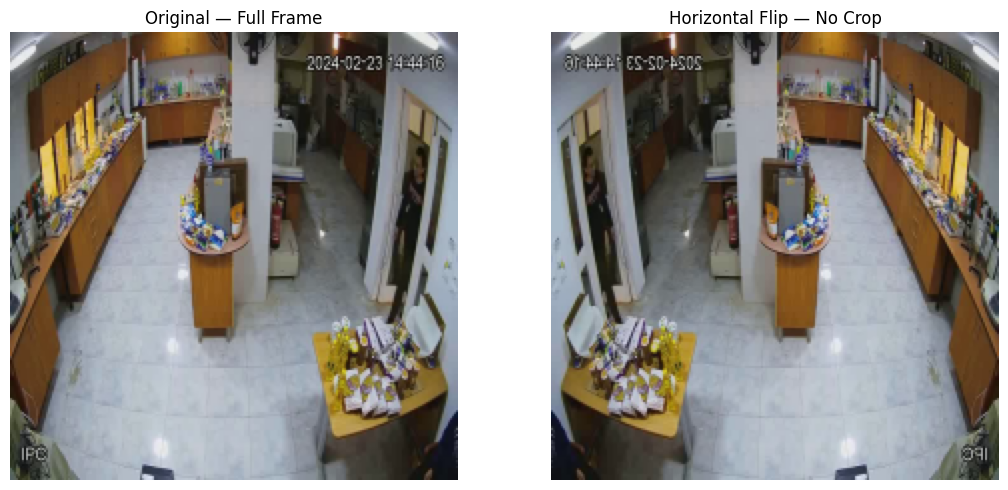

In [9]:
# Visual verification: FORCE horizontal flip for demonstration
# This does NOT change the training augmentation probability.

example = get_cached_clip(train_rows.iloc[0])

# Flip all frames horizontally (no crop)
flipped = example[:, :, ::-1, :].copy()

# Verify correct flipping
assert np.array_equal(flipped[0], example[0][:, ::-1, :])
print("Horizontal Flip: PASS")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].imshow(example[0])
axes[0].set_title("Original — Full Frame")

axes[1].imshow(flipped[0])
axes[1].set_title("Horizontal Flip — No Crop")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:

# 6 — Train classifier, then fine-tune last 2 transformer blocks
# Model selection uses VALIDATION ONLY.

import torch.nn.functional as F

HEAD_EPOCHS = 2
FINETUNE_EPOCHS = 6
PATIENCE = 3

HEAD_PATH = OUT / "best_head_only.pt"
BEST_PATH = OUT / "best_finetuned.pt"
HISTORY_PATH = OUT / "training_history.csv"

criterion = nn.CrossEntropyLoss()
history = []


def train_one_epoch(optimizer, scaler):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    total_loss = 0.0
    true_labels, predictions = [], []

    trainable = [
        p for p in model.parameters() if p.requires_grad
    ]

    num_batches = len(train_loader)

    for step, (clips, labels) in enumerate(
        tqdm(train_loader, leave=False), start=1
    ):
        clips = clips.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Correct scaling for the last accumulation group too.
        group_start = ((step - 1) // GRAD_ACCUM) * GRAD_ACCUM
        group_size = min(
            GRAD_ACCUM, num_batches - group_start
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = model(pixel_values=clips).logits
            loss = criterion(logits, labels)

        scaler.scale(loss / group_size).backward()

        if step % GRAD_ACCUM == 0 or step == num_batches:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(trainable, 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        total_loss += loss.item() * len(labels)
        true_labels.extend(labels.cpu().tolist())
        predictions.extend(logits.detach().argmax(1).cpu().tolist())

    return {
        "loss": total_loss / len(train_ds),
        "f1": f1_score(
            true_labels, predictions,
            average="macro", zero_division=0
        )
    }


@torch.inference_mode()
def evaluate_loader(loader):
    model.eval()

    total_loss = 0.0
    true_labels, predictions = [], []

    for clips, labels in loader:
        clips = clips.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = model(pixel_values=clips).logits
            loss = criterion(logits, labels)

        total_loss += loss.item() * len(labels)
        true_labels.extend(labels.cpu().tolist())
        predictions.extend(logits.argmax(1).cpu().tolist())

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(true_labels, predictions),
        "f1": f1_score(
            true_labels, predictions,
            average="macro", zero_division=0
        )
    }


def save_checkpoint(path, stage, epoch, val_f1):
    torch.save({
        "model": {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        },
        "stage": stage,
        "epoch": epoch,
        "val_f1": float(val_f1),
        "model_id": MODEL_ID,
        "labels": {0: "Normal", 1: "Shoplifting"},
        "frames": NUM_FRAMES,
        "size": IMAGE_SIZE,
        "crop": False,
        "sampling": "1 FPS then uniform 16 frames"
    }, path)


def run_stage(stage, epochs, optimizer, save_path):
    scaler = torch.amp.GradScaler(
        "cuda", enabled=USE_AMP
    )

    best_f1 = -1.0
    best_loss = float("inf")
    no_improvement = 0

    for epoch in range(1, epochs + 1):
        start = time.perf_counter()

        tr = train_one_epoch(optimizer, scaler)
        val = evaluate_loader(val_loader)

        seconds = time.perf_counter() - start

        record = {
            "stage": stage,
            "epoch": epoch,
            "train_loss": tr["loss"],
            "train_f1": tr["f1"],
            "val_loss": val["loss"],
            "val_accuracy": val["accuracy"],
            "val_f1": val["f1"],
            "seconds": seconds
        }

        history.append(record)
        pd.DataFrame(history).to_csv(
            HISTORY_PATH, index=False
        )

        print(
            f"{stage} | Epoch {epoch}/{epochs} | "
            f"Train F1: {tr['f1']:.4f} | "
            f"Val F1: {val['f1']:.4f} | "
            f"Val Loss: {val['loss']:.4f} | "
            f"Time: {seconds:.1f}s"
        )

        if not np.isfinite(val["loss"]):
            raise RuntimeError("Non-finite validation loss.")

        improved = (
            val["f1"] > best_f1 + 1e-6
            or (
                abs(val["f1"] - best_f1) <= 1e-6
                and val["loss"] < best_loss
            )
        )

        if improved:
            best_f1 = val["f1"]
            best_loss = val["loss"]
            no_improvement = 0

            save_checkpoint(
                save_path, stage, epoch, best_f1
            )

            print("  Saved best validation checkpoint.")
        else:
            no_improvement += 1

        if no_improvement >= PATIENCE:
            print("Early stopping:", stage)
            break

    return best_f1


# -------------------------------------------------
# Stage A: Classifier head training
# -------------------------------------------------

model.requires_grad_(False)
model.classifier.requires_grad_(True)

if getattr(model, "fc_norm", None) is not None:
    model.fc_norm.requires_grad_(True)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=3e-4,
    weight_decay=0.01
)

print("\nSTAGE A: Training classifier head")

head_f1 = run_stage(
    "head", HEAD_EPOCHS, optimizer, HEAD_PATH
)

# Start fine-tuning from best head checkpoint.
head_ckpt = torch.load(
    HEAD_PATH, map_location="cpu", weights_only=True
)
model.load_state_dict(head_ckpt["model"])
model.to(device)

del optimizer, head_ckpt
if USE_AMP:
    torch.cuda.empty_cache()

# -------------------------------------------------
# Stage B: Fine-tune last 2 transformer blocks
# -------------------------------------------------

model.requires_grad_(False)

last_blocks = model.videomae.encoder.layer[-2:]

for block in last_blocks:
    block.requires_grad_(True)

model.classifier.requires_grad_(True)

if getattr(model, "fc_norm", None) is not None:
    model.fc_norm.requires_grad_(True)

encoder_params = [
    p for block in last_blocks
    for p in block.parameters() if p.requires_grad
]

head_params = [
    p for p in model.classifier.parameters()
    if p.requires_grad
]

if getattr(model, "fc_norm", None) is not None:
    head_params += list(model.fc_norm.parameters())

optimizer = torch.optim.AdamW(
    [
        {"params": encoder_params, "lr": 1e-5},
        {"params": head_params, "lr": 1e-4}
    ],
    weight_decay=0.01
)

print("\nSTAGE B: Fine-tuning final transformer blocks")
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters()
        if p.requires_grad)
)

finetuned_f1 = run_stage(
    "finetune", FINETUNE_EPOCHS, optimizer, BEST_PATH
)

print("\nBest Head Validation F1:", round(head_f1, 4))
print("Best Fine-tuned Validation F1:", round(finetuned_f1, 4))
print("Fine-tuned model saved:", BEST_PATH)
print("Test set has NOT been evaluated yet.")


STAGE A: Training classifier head


  0%|          | 0/228 [00:00<?, ?it/s]

head | Epoch 1/2 | Train F1: 0.5185 | Val F1: 0.3361 | Val Loss: 0.6835 | Time: 65.8s
  Saved best validation checkpoint.


  0%|          | 0/228 [00:00<?, ?it/s]

head | Epoch 2/2 | Train F1: 0.6031 | Val F1: 0.6788 | Val Loss: 0.6617 | Time: 37.8s
  Saved best validation checkpoint.

STAGE B: Fine-tuning final transformer blocks
Trainable parameters: 3549698


...

finetune | Epoch 4/6 | Train F1: 0.8574 | Val F1: 0.8010 | Val Loss: 0.5016 | Time: 42.5s


  0%|          | 0/228 [00:00<?, ?it/s]

finetune | Epoch 5/6 | Train F1: 0.8728 | Val F1: 0.8641 | Val Loss: 0.4283 | Time: 38.9s
  Saved best validation checkpoint.


  0%|          | 0/228 [00:00<?, ?it/s]

finetune | Epoch 6/6 | Train F1: 0.8925 | Val F1: 0.9011 | Val Loss: 0.3592 | Time: 39.1s
  Saved best validation checkpoint.

Best Head Validation F1: 0.6788
Best Fine-tuned Validation F1: 0.9011
Fine-tuned model saved: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet/shoplifting_pretrained_videomae_small/best_finetuned.pt
Test set has NOT been evaluated yet.


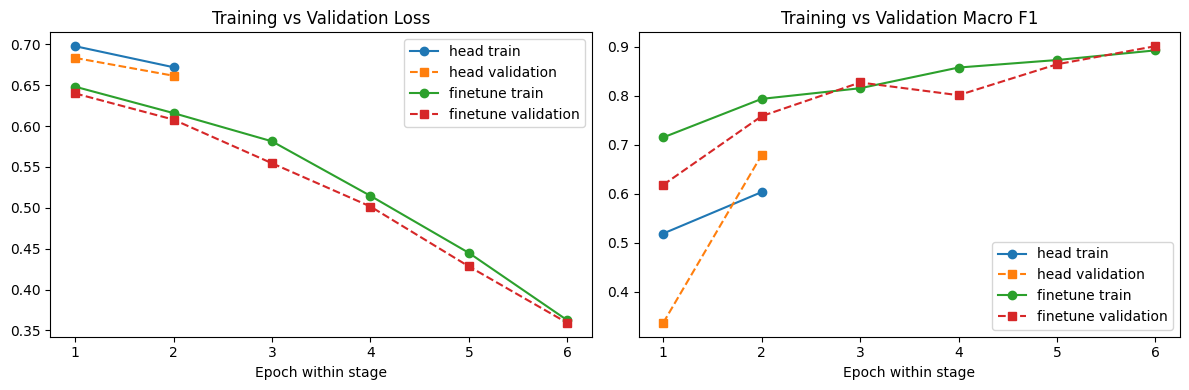

Saved: /content/drive/MyDrive/Cellula/Shoplifting-Detection/DataSet/shoplifting_pretrained_videomae_small/training_curves.png


In [7]:

# 7 — Training history visualization

results = pd.read_csv(HISTORY_PATH)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for stage, group in results.groupby("stage", sort=False):
    axes[0].plot(
        range(1, len(group) + 1),
        group["train_loss"],
        marker="o",
        label=f"{stage} train"
    )
    axes[0].plot(
        range(1, len(group) + 1),
        group["val_loss"],
        marker="s",
        linestyle="--",
        label=f"{stage} validation"
    )

    axes[1].plot(
        range(1, len(group) + 1),
        group["train_f1"],
        marker="o",
        label=f"{stage} train"
    )
    axes[1].plot(
        range(1, len(group) + 1),
        group["val_f1"],
        marker="s",
        linestyle="--",
        label=f"{stage} validation"
    )

axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch within stage")
axes[0].legend()

axes[1].set_title("Training vs Validation Macro F1")
axes[1].set_xlabel("Epoch within stage")
axes[1].legend()

plt.tight_layout()

plot_path = OUT / "training_curves.png"
plt.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)

Final Test:   0%|          | 0/48 [00:00<?, ?it/s]


VideoMAE Small — Final Test Metrics
{
  "n_test": 95,
  "accuracy": 0.8947368421052632,
  "precision_macro": 0.8978085867620751,
  "recall_macro": 0.894281914893617,
  "f1_macro": 0.8944444444444444,
  "shoplifting_recall": 0.9375
}

Classification Report:
              precision    recall  f1-score   support

      Normal       0.93      0.85      0.89        47
 Shoplifting       0.87      0.94      0.90        48

    accuracy                           0.89        95
   macro avg       0.90      0.89      0.89        95
weighted avg       0.90      0.89      0.89        95


Confusion Matrix:
[[40  7]
 [ 3 45]]


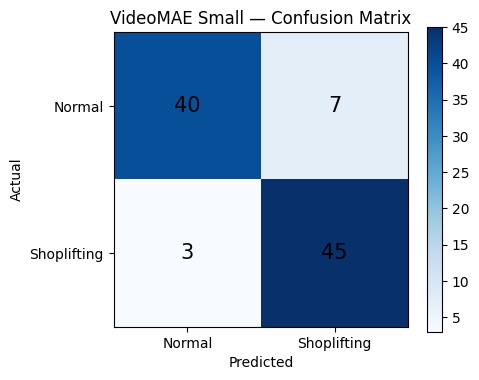


Saved metrics, predictions and confusion matrix.


In [8]:

# 8 — Final test evaluation
# Do not use this result to tune further experiments.

assert BEST_PATH.is_file(), "Run fine-tuning first."

checkpoint = torch.load(
    BEST_PATH,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model"])
model.to(device)
model.eval()

all_true = []
all_pred = []
all_prob = []

with torch.inference_mode():
    for clips, labels in tqdm(
        test_loader, desc="Final Test"
    ):
        clips = clips.to(device)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=USE_AMP
        ):
            logits = model(pixel_values=clips).logits

        probs = torch.softmax(
            logits.float(), dim=1
        ).cpu().numpy()

        all_true.extend(labels.tolist())
        all_pred.extend(probs.argmax(axis=1).tolist())
        all_prob.extend(probs[:, 1].tolist())

metrics = {
    "n_test": len(all_true),
    "accuracy": accuracy_score(all_true, all_pred),
    "precision_macro": precision_score(
        all_true, all_pred,
        average="macro", zero_division=0
    ),
    "recall_macro": recall_score(
        all_true, all_pred,
        average="macro", zero_division=0
    ),
    "f1_macro": f1_score(
        all_true, all_pred,
        average="macro", zero_division=0
    ),
    "shoplifting_recall": recall_score(
        all_true, all_pred,
        pos_label=1, zero_division=0
    )
}

print("\nVideoMAE Small — Final Test Metrics")
print(json.dumps(metrics, indent=2))

print("\nClassification Report:")
print(classification_report(
    all_true, all_pred,
    labels=[0, 1],
    target_names=["Normal", "Shoplifting"],
    zero_division=0
))

cm = confusion_matrix(
    all_true, all_pred, labels=[0, 1]
)

print("\nConfusion Matrix:")
print(cm)

predictions = test_rows[
    ["sha256", "relative_path", "label"]
].copy()

predictions["predicted"] = all_pred
predictions["shoplifting_probability"] = all_prob

predictions.to_csv(
    OUT / "final_test_predictions.csv",
    index=False
)

with open(OUT / "final_test_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            fontsize=15
        )

ax.set_xticks([0, 1], ["Normal", "Shoplifting"])
ax.set_yticks([0, 1], ["Normal", "Shoplifting"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("VideoMAE Small — Confusion Matrix")

plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(
    OUT / "confusion_matrix.png",
    dpi=160, bbox_inches="tight"
)
plt.show()

print("\nSaved metrics, predictions and confusion matrix.")